In [ ]:
# ============================================================
# Setup
# Load all packages and report their versions for reproducibility.
# ============================================================

# Load the required packages

# render matplotlib figures inside the notebook
%matplotlib inline   

# scitnific computing and plotting
import numpy as np  
import pandas as pd 
import xarray as xr 
import matplotlib.pyplot as plt 
import seaborn as sns  
# HDDM related packages
import pymc as pm  
import hddm 
import kabuki 
import arviz as az  

# Report the loaded package versions for reproducibility
print("The current HDDM version is: ", hddm.__version__)
print("The current kabuki version is: ", kabuki.__version__)
print("The current PyMC version is: ", pm.__version__)
print("The current ArviZ version is: ", az.__version__)

import warnings   # used to suppress non-critical warnings
warnings.filterwarnings('ignore')   # keep the notebook output clean

The current HDDM version is:  1.0.1RC
The current kabuki version is:  0.6.5RC4
The current PyMC version is:  2.3.8
The current ArviZ version is:  1.1.0


## Load and recode the data
- Load the trial-level dataset and recode the dot features (color / shape) into binary 1/0 codes.

In [ ]:
# Load the trial-level dataset (adjust the relative path to your local layout)
data = hddm.load_csv('../../../3_Data/CleanData/data_all.csv')
data['response'] = data['correct']   # response = observed accuracy (1/0), used for accuracy coding

# Red and square are 1, blue and circle are 0
# Recode the dot-array features into binary codes (1/0)
data = data.assign(
    dot_color=data['dot_color_final'].map({'["hsl(0, 50%, 50%)","hsl(225, 50%, 50%)"]': 1, '["hsl(225, 50%, 50%)","hsl(0, 50%, 50%)"]': 0}),   # red-dominant array = 1, blue-dominant = 0
    dot_shape=data['dot_shape'].map({'square': 1, 'circle': 0})   # square = 1, circle = 0
)

## Identity task and identity-relevant task

- The data of the three tasks must be fitted separately
- Prepare the identity-choice & identity-relevant data

In [ ]:
# Keep only the identity-choice (overlap) and identity-relevant trials;
data_id = data[data["task_type"].isin(["overlap", "relevant"])].copy()

# Add a choice column: 1=self, 0=other
# - self-association + correct → 1; self-association + error → 0
# - other-association + correct → 0; other-association + error → 1
# Recode each trial into an upper-boundary (1) / lower-boundary (0) choice
data_id["choice"] = data_id.apply(
    lambda row: 1 if (row["association"] == "self" and row["correct"] == 1)    # self + correct -> upper boundary
    or (row["association"] == "other" and row["correct"] == 0) else 0,   # other + error -> upper boundary (a self response)
    axis=1   # apply the lambda row by row
)

data_id["stim"] = data_id["association"].map({"self": 1, "other": 0})   # numeric stim code used by the z link function

### Model fitting

- Fit the HDDM model (identity-choice & identity-relevant)

In [ ]:
# Response column = observed accuracy (1/0), used with accuracy coding
data_id['response'] = data_id['correct']

# Define the link function
# Custom link function: flips z so that z > 0.5 means a bias toward the upper
# (chosen) boundary regardless of the stim code
def z_link_func(x, data=data_id):
    stim = data.stim.loc[x.index] # stim in the data is coded as 1 and 0
    z_flip = (stim * x) + (1 - x) * (1 - stim)   # keep x when stim = 1, mirror it (1 - x) when stim = 0
    return z_flip   # return the flipped z values

# Build the regression model

# Define the regression structure for HDDMRegressor
model_reg = [
    {'model': "v ~ 1 + task_type*association", 'link_func': lambda x: x},
    {'model': "z ~ 1 + task_type", 'link_func':  z_link_func}  
] 
 
# Build the hierarchical DDM with regressions on v and z
m_id_vz = hddm.HDDMRegressor(
    data_id,   # data of the two tasks
    model_reg,   # the v/z regression definitions above
    bias=True,   # include a bias parameter
    include=['v', 'a', 't','z','sv','sz'],   # parameters to estimate (sv/sz = trial-level variability)
    group_only_regressors=False   # the regressors vary at the trial level
)

# Draw posterior samples (5000 per chain, 1000 burn-in) and return an InferenceData object
m_id_vz_idata = m_id_vz.sample(5000, burn=1000, chains=4, return_infdata=True, dbname = 'm_id_vz.db', db = 'pickle')
m_id_vz.save('m_id_vz.hddm')   # save the fitted model

- Summarize the posterior of every parameter

In [ ]:
# Keep only parameter rows that do not contain "_subj."
summary = az.summary(m_id_vz_idata)
group_params = summary[~summary.index.str.contains('_subj.')]
print(group_params)   # show only the group-level parameter summary

## Identity-irrelevant task
Because the options of the identity-irrelevant task (square/circle and red/blue) differ in meaning, tasks requiring different judgments must be fitted separately

In [ ]:
# Prepare the identity-irrelevant data

# Shape group: identity-irrelevant task corresponds to color judgment
# Shape group judged color (the non-associated dimension) -> identity-irrelevant task
data_irrcolor = data.query("task_type == 'irrelevant' and group == 'shape'").copy()
# Color group: identity-irrelevant task corresponds to shape judgment
# Color group judged shape (the non-associated dimension) -> identity-irrelevant task
data_irrshape = data.query("task_type == 'irrelevant' and group == 'color'").copy()

# Code the choices of the shape-judgment data (1 = upper boundary = square)
data_irrshape["choice"] = data_irrshape.apply(
    lambda row: 1 if (row["dot_shape"] == 1 and row["correct"] == 1)    # square + correct -> upper boundary
    or (row["dot_shape"] == 0 and row["correct"] == 0) else 0,   # circle + error -> upper boundary
    axis=1  
)

# Code the choices of the color-judgment data (1 = upper boundary = red)
data_irrcolor["choice"] = data_irrcolor.apply(
    lambda row: 1 if (row["dot_color"] == 1 and row["correct"] == 1)    # red + correct -> upper boundary
    or (row["dot_color"] == 0 and row["correct"] == 0) else 0,   # blue + error -> upper boundary
    axis=1   
)

### Shape identity-irrelevant task
#### Model fitting

- Fit the HDDM model (identity-irrelevant: shape judgment)

In [ ]:
# Shape identity-irrelevant task
# Response column = observed accuracy (1/0)
data_irrshape["response"] = data_irrshape["correct"]

# Define the link function
# Same z flip, applied to the shape-judgment data
def z_link_func(x, data=data_irrshape):
    stim = data.dot_shape.loc[x.index] # stim in the data is coded as 1 and 0
    z_flip = (stim * x) + (1 - x) * (1 - stim)   # keep x when stim = 1, 1-x when stim = 0
    return z_flip

# Build the regression model
# Regression structure of the identity-irrelevant (shape-judgment) model
model_reg = [
    {'model': "v ~ 1 + association", 'link_func': lambda x: x},   # only v varies with association
    {'model': "z ~ 1", 'link_func': z_link_func}   # z intercept only, with the flip
] 
 
# Build the identity-irrelevant (shape-judgment) model
m_irrshape_v = hddm.HDDMRegressor(
    data_irrshape,   # data
    model_reg,
    bias=True,
    include=['v', 'a', 't','z','sv'],   # parameters to estimate
    group_only_regressors=False
)

# Draw posterior samples and return the InferenceData object
m_irrshape_v_idata = m_irrshape_v.sample(5000, burn=1000, chains=4, return_infdata=True, dbname = 'm_irrshape_v.db', db = 'pickle')
m_irrshape_v.save('m_irrshape_v.hddm')   # save the fitted model

- Summarize the posterior of every parameter

In [ ]:
summary = az.summary(m_irrshape_v_idata)
group_params = summary[~summary.index.str.contains('_subj.')]  
print(group_params)   # show only the group-level parameter summary

### Color identity-irrelevant task
#### Model fitting

- Fit the HDDM model (identity-irrelevant: color judgment)

In [ ]:
# Color identity-irrelevant task
# Response column = observed accuracy (1/0)
data_irrcolor["response"] = data_irrcolor["correct"]

# Define the link function
# Same z flip, applied to the color-judgment data
def z_link_func(x, data=data_irrcolor):
    stim = data.dot_color.loc[x.index] # stim in the data is coded as 1 and 0
    z_flip = (stim * x) + (1 - x) * (1 - stim)   # keep x when stim = 1, mirror it when stim = 0
    return z_flip

# Build the regression model
# Regression structure of the identity-irrelevant (color-judgment) model
model_reg = [
    {'model': "v ~ 1 + association", 'link_func': lambda x: x},   # only v varies with association
    {'model': "z ~ 1", 'link_func': z_link_func}   # z intercept only, with the flip
] 
 
# Build the identity-irrelevant (color-judgment) model
m_irrcolor_v = hddm.HDDMRegressor(
    data_irrcolor,   # data
    model_reg,
    bias=True,
    include=['v', 'a', 't', 'z','sv'],   # parameters to estimate
    group_only_regressors=False
)

# Draw posterior samples and return the InferenceData object
m_irrcolor_v_idata = m_irrcolor_v.sample(5000, burn=1000, chains=4, return_infdata=True, dbname = 'm_irrcolor_v.db', db = 'pickle')
m_irrcolor_v.save('m_irrcolor_v.hddm')   # save the fitted model

- Summarize the posterior of every parameter

In [ ]:
summary = az.summary(m_irrcolor_v_idata)
group_params = summary[~summary.index.str.contains('_subj.')]  
print(group_params)   # show only the group-level parameter summary

## Posterior predictive check

- Reload the fitted models and generate posterior predictive data

In [ ]:
# Reload the fitted models (fitted in the cells above)
id_vz = hddm.load('m_id_vz.hddm') # id-choice and id-trlrvant task
irrshape_v = hddm.load('m_irrshape_v.hddm')   # id-irrelevant: shape-judgment model
irrcolor_v = hddm.load('m_irrcolor_v.hddm')   # id-irrelevant: color-judgment model

In [ ]:
# Generate posterior predictive data
ppc_data_id = hddm.utils.post_pred_gen(id_vz, n_samples=20)
ppc_data_irrshape = hddm.utils.post_pred_gen(irrshape_v, n_samples=20)
ppc_data_irrcolor = hddm.utils.post_pred_gen(irrcolor_v, n_samples=20)

- Compare the observed and predicted signed-RT densities for each model

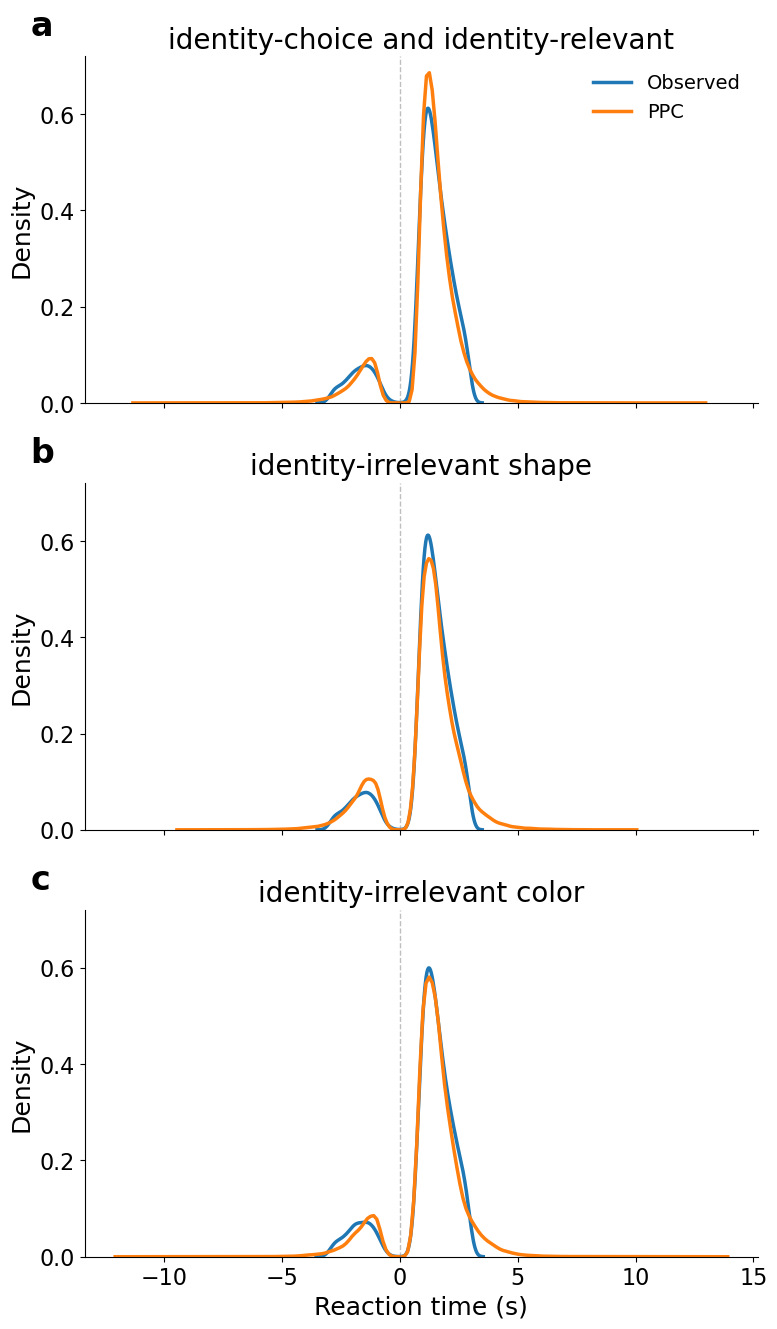

In [ ]:
# Map each model to its posterior predictive data and the observed data to compare against
ppc_dict = {
    "m1": {"ppc": ppc_data_id,       "obs": data_id},   # identity-choice & identity-relevant model
    "m2": {"ppc": ppc_data_irrshape, "obs": data_irrshape},   # shape-judgment model
    "m3": {"ppc": ppc_data_irrcolor, "obs": data_irrcolor},   # color-judgment model
}

# Panel titles of the three models
panel_titles = {
    "m1": "identity-choice and identity-relevant",
    "m2": "identity-irrelevant shape",
    "m3": "identity-irrelevant color",
}


# Plot observed vs. predicted RT densities, with RTs signed by accuracy
# (positive = correct-response side, negative = error side)
def plot_rt_density_signed(ppc_dict):

    plt.rcParams.update({'font.size': 14})   # global base font size

    color_ppc = "C1"      # orange —— PPC
    color_obs = "C0"      # blue —— observed data

    # ============================================================
    # Helper function: convert PPC rt to signed rt
    # ============================================================
    # Collect signed RTs across posterior predictive draws, merged with the observed accuracy
    def collect_ppc_rt_signed(ppc, obs_data):
            # Give each observed trial a running index so the PPC rows can be joined to it
            obs_reset = (obs_data.reset_index(drop=True)
                                .reset_index()   # create an index column
                                .rename(columns={"index": "trial_idx"}))   # name it "trial_idx"

            ppc_df = ppc.reset_index().rename(columns={"index": "trial_idx"})   # the PPC data gets the same trial index
            # Attach the observed accuracy to each simulated trial via the trial index
            ppc_df = ppc_df.merge(
                        obs_reset[["trial_idx", "correct"]],   # only the index and accuracy columns are needed
                        on="trial_idx", how="left"   # left join on the trial index
                    )

            n_nan = ppc_df["correct"].isna().sum()   # count trials whose accuracy could not be joined
            if n_nan > 0:   # warn if some trials failed to join (index misalignment)
                print(f"After merge, {n_nan} rows have NaN in correct; the index may be misaligned.")

            # Sign the RTs: positive = correct, negative = error
            ppc_df["rt_signed"] = np.where(
                        ppc_df["correct"] == 1,   # correct trials
                        np.abs(ppc_df["rt"]),   # keep the magnitude as is
                        -np.abs(ppc_df["rt"])   # errors get a negative sign
                    )

            all_draws = ppc_df["draw"].unique()   # list of the posterior predictive draws
            n_keep = min(len(all_draws), 50)   # cap the number of draws used for the density plot
            keep_draws = np.random.choice(all_draws, n_keep, replace=False)   # pick draws at random without replacement

            vals = []
            for d in keep_draws:   # collect the signed RTs of each selected draw
                v = ppc_df[ppc_df["draw"] == d]["rt_signed"].values   # signed RTs of draw d
                vals.append(v)   # gather them in a list
            return np.concatenate(vals)   # return all draws stacked into one array

    # ============================================================
    # Helper function: convert observed rt to signed rt
    # ============================================================
    # Sign the observed RTs the same way (correct +, error -)
    def get_obs_rt_signed(obs_data):
            return np.where(   # vectorized sign assignment
                obs_data["correct"].values == 1,   # correct trials
                np.abs(obs_data["rt"].values),   # positive RT
                -np.abs(obs_data["rt"].values)   # negative RT for errors
            )

    # ============================================================
    # Layout: n_models rows × 1 column
    # ============================================================
    n_models = len(ppc_dict)   # one panel per model
    # Create a column of panels (one per model) with shared axes
    fig, axes = plt.subplots(n_models, 1, figsize=(8, 4.5 * n_models),
                                    sharex=True, sharey=True, dpi=100)   # shared x/y scales across the panels
    if n_models == 1:   # make sure axes is always an array for uniform indexing
        axes = np.array([axes])

    panel_counter = [0]   # mutable counter for the panel labels
    
    def next_label():   # returns a, b, c, ... one letter per panel
        idx = panel_counter[0]   # current label index
        panel_counter[0] += 1   # advance the counter
        return chr(ord('a') + idx)   # convert the index into a lowercase letter

    for row_idx, (model_name, entry) in enumerate(ppc_dict.items()):   # loop over the models
        ppc      = entry["ppc"]   # the posterior predictive data
        obs_data = entry["obs"]   # the observed data to compare against

        ax = axes[row_idx]   # the current panel

        # ---- Observed KDE (blue) ----
        obs_rt = get_obs_rt_signed(obs_data)   # signed observed RTs
        if len(obs_rt) > 2:   # only plot when there are enough data points
            # KDE of the observed RT density
            sns.kdeplot(obs_rt, ax=ax, color=color_obs,
                        linewidth=2.5, linestyle="-",   # solid line
                        label="Observed")   # legend entry

        # ---- PPC KDE (orange) ----
        pp_rt = collect_ppc_rt_signed(ppc, obs_data)   # signed posterior predictive RTs
        if pp_rt is not None and len(pp_rt) > 2:   # guard against empty predictive data
            # KDE of the posterior predictive RT density
            sns.kdeplot(pp_rt, ax=ax, color=color_ppc,
                        linewidth=2.5, linestyle="-",   # solid line
                        label="PPC")   # legend entry

        # ---- Reference line at 0 ----
        # Vertical reference line at 0 (boundary between the correct and error sides)
        ax.axvline(0, color="gray", linestyle="--",
                   linewidth=1, alpha=0.5)   # subtle dashed line

        # panel label
        ax.text(-0.08, 1.04, next_label(),   # place the panel letter outside the top-left corner
                transform=ax.transAxes,   # coordinates relative to the axes
                fontsize=24, fontweight='bold',   # large bold panel letter
                ha='left', va='bottom')   # align to the top-left corner

        # Set the panel title
        title = panel_titles.get(model_name, model_name)   # look up the panel title
        ax.set_title(title, fontsize=20)   # set the panel title

        # Axis labels and ticks
        if row_idx == n_models - 1:   # only label the x-axis on the bottom panel
            ax.set_xlabel("Reaction time (s)", fontsize=18)   # x-axis label
        ax.set_ylabel("Density", fontsize=18)   # y-axis label
        ax.tick_params(axis='both', labelsize=16)   # tick label size

        ax.spines['top'].set_visible(False)   # hide the top border
        ax.spines['right'].set_visible(False)   # hide the right border
        ax.grid(False)   # no background grid

        # only add to the first panel, showing Observed and PPC
        if row_idx == 0:   # only the first panel carries the legend
            ax.legend(loc="upper right", fontsize=14, frameon=False)   # legend without a surrounding box

    plt.tight_layout()   # remove overlapping elements
    return fig   # hand the figure back to the caller


# Run the posterior predictive check plot
fig = plot_rt_density_signed(ppc_dict=ppc_dict)
# Save the figure as a vector graphic
fig.savefig("Fig/ppc_rt_density_signed.svg", format="svg",
            bbox_inches="tight", dpi=300)   # trim whitespace at high resolution
plt.show()   # render the figure in the notebook